# LAB 1 - Bài 5a (Trang 45): Luật kết hợp trên dữ liệu Online Retail - nước Đức (Germany)
SV: Hồng Kim Dung - 6451071009

In [1]:
!pip install -q mlxtend openpyxl
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings; warnings.filterwarnings("ignore")
print("Hồng Kim Dung - 6451071009")

Hồng Kim Dung - 6451071009


## Câu 1: Đọc dữ liệu và tiền xử lý (yêu cầu 1, 2)

In [2]:
print("Hồng Kim Dung - 6451071009")

df = pd.read_excel("Online Retail.xlsx")
print(df.shape)
df.head()

Hồng Kim Dung - 6451071009
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Hồng Kim Dung - 6451071009")

df["Description"] = df["Description"].str.strip()          # cắt ký tự thừa ở tên mặt hàng
df = df.dropna(subset=["InvoiceNo"])                        # xóa dòng không có số hóa đơn
df["InvoiceNo"] = df["InvoiceNo"].astype("str")             # chuyển về kiểu chuỗi
print(df.shape); df.info()

Hồng Kim Dung - 6451071009
(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540454 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## Câu 2: Xóa hóa đơn tín dụng và thống kê theo quốc gia (yêu cầu 3, 4)

In [4]:
print("Hồng Kim Dung - 6451071009")

df = df[~df["InvoiceNo"].str.contains("C")]                 # hóa đơn tín dụng chứa ký tự 'C'
print(df.shape)
df["Country"].value_counts()

Hồng Kim Dung - 6451071009
(532621, 8)


,count
Country,
United Kingdom,487622
Germany,9042
France,8408
EIRE,7894
Spain,2485
Netherlands,2363
Belgium,2031
Switzerland,1967
Portugal,1501


## Câu 3: Lấy dữ liệu nước Đức (Germany), gom nhóm, chuyển dạng hot encoding (yêu cầu 5, 6)

In [5]:
print("Hồng Kim Dung - 6451071009")

de = df[df["Country"] == "Germany"]
grouped = de.groupby(["InvoiceNo","Description"])["Quantity"].sum()
grouped.head(10)

Hồng Kim Dung - 6451071009


InvoiceNo  Description                        
536527     3 HOOK HANGER MAGIC GARDEN             12
           5 HOOK HANGER MAGIC TOADSTOOL          12
           5 HOOK HANGER RED MAGIC TOADSTOOL      12
           ASSORTED COLOUR LIZARD SUCTION HOOK    24
           CHILDREN'S CIRCUS PARADE MUG           12
           HOMEMADE JAM SCENTED CANDLES           12
           HOT WATER BOTTLE BABUSHKA               4
           JUMBO BAG OWLS                         10
           JUMBO BAG WOODLAND ANIMALS             10
           MULTI COLOUR SILVER T-LIGHT HOLDER     12
Name: Quantity, dtype: int64

In [6]:
print("Hồng Kim Dung - 6451071009")

# Mỗi dòng là một hóa đơn, mỗi cột là một mặt hàng, giá trị là tổng số lượng mua
basket = grouped.unstack().fillna(0)
print(basket.shape)
basket.iloc[:5, :6]

Hồng Kim Dung - 6451071009
(457, 1695)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT
InvoiceNo,,,,,,
536527,0.0,0.0,0.0,0.0,0.0,0.0
536840,0.0,0.0,0.0,0.0,0.0,0.0
536861,0.0,0.0,0.0,0.0,0.0,0.0
536967,0.0,0.0,0.0,0.0,0.0,0.0
536983,0.0,0.0,0.0,0.0,0.0,0.0


## Câu 4: Chuyển sang one-hot encoding và xóa POSTAGE (yêu cầu 7, 8)

In [7]:
print("Hồng Kim Dung - 6451071009")

# Giá trị >= 1 -> 1 (True), ngược lại -> 0 (False)
basket_sets = (basket >= 1).astype(bool)
print(basket_sets.shape)
basket_sets.iloc[:5, :6]

Hồng Kim Dung - 6451071009
(457, 1695)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT
InvoiceNo,,,,,,
536527,False,False,False,False,False,False
536840,False,False,False,False,False,False
536861,False,False,False,False,False,False
536967,False,False,False,False,False,False
536983,False,False,False,False,False,False


In [8]:
print("Hồng Kim Dung - 6451071009")

basket_sets = basket_sets.drop("POSTAGE", axis=1)           # POSTAGE là cước phí, không phải mặt hàng
print("POSTAGE" in basket_sets.columns, basket_sets.shape)

Hồng Kim Dung - 6451071009
False (457, 1694)


## Câu 5: Apriori, luật kết hợp và biểu đồ (min_sup = 5%, min_conf = 50%)

In [9]:
print("Hồng Kim Dung - 6451071009")

t0 = time.time()
frequent_itemsets = apriori(basket_sets, min_support=0.05, use_colnames=True)
t_apriori = time.time() - t0
frequent_itemsets["length"] = frequent_itemsets["itemset" if "itemset" in frequent_itemsets else "itemsets"].apply(len)
print("Số tập phổ biến:", len(frequent_itemsets), "| thời gian Apriori: %.2f giây" % t_apriori)
frequent_itemsets.sort_values("support", ascending=False).head(15)

Hồng Kim Dung - 6451071009
Số tập phổ biến: 59 | thời gian Apriori: 0.15 giây


,support,itemsets,length
35,0.245077,(ROUND SNACK BOXES SET OF4 WOODLAND),1
34,0.157549,(ROUND SNACK BOXES SET OF 4 FRUITS),1
24,0.137856,(PLASTERS IN TIN WOODLAND ANIMALS),1
31,0.137856,(REGENCY CAKESTAND 3 TIER),1
56,0.131291,"(ROUND SNACK BOXES SET OF4 WOODLAND, ROUND SNA...",2
48,0.126915,(WOODLAND CHARLOTTE BAG),1
21,0.115974,(PLASTERS IN TIN CIRCUS PARADE),1
22,0.107221,(PLASTERS IN TIN SPACEBOY),1
0,0.102845,(6 RIBBONS RUSTIC CHARM),1
44,0.102845,(SPACEBOY LUNCH BOX),1


In [10]:
print("Hồng Kim Dung - 6451071009")

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
print("Số luật:", len(rules))
rules[["antecedents","consequents","support","confidence","lift"]]

Hồng Kim Dung - 6451071009
Số luật: 8


,antecedents,consequents,support,confidence,lift
0,(PLASTERS IN TIN CIRCUS PARADE),(PLASTERS IN TIN WOODLAND ANIMALS),0.067834,0.584906,4.242887
1,(PLASTERS IN TIN SPACEBOY),(PLASTERS IN TIN WOODLAND ANIMALS),0.061269,0.571429,4.145125
2,(PLASTERS IN TIN WOODLAND ANIMALS),(ROUND SNACK BOXES SET OF4 WOODLAND),0.074398,0.539683,2.202098
3,(RED RETROSPOT CHARLOTTE BAG),(WOODLAND CHARLOTTE BAG),0.059081,0.843750,6.648168
4,(ROUND SNACK BOXES SET OF4 WOODLAND),(ROUND SNACK BOXES SET OF 4 FRUITS),0.131291,0.535714,3.400298
5,(ROUND SNACK BOXES SET OF 4 FRUITS),(ROUND SNACK BOXES SET OF4 WOODLAND),0.131291,0.833333,3.400298
6,(SPACEBOY LUNCH BOX),(ROUND SNACK BOXES SET OF4 WOODLAND),0.070022,0.680851,2.778116
7,(WOODLAND CHARLOTTE BAG),(ROUND SNACK BOXES SET OF4 WOODLAND),0.063457,0.500000,2.040179


Hồng Kim Dung - 6451071009


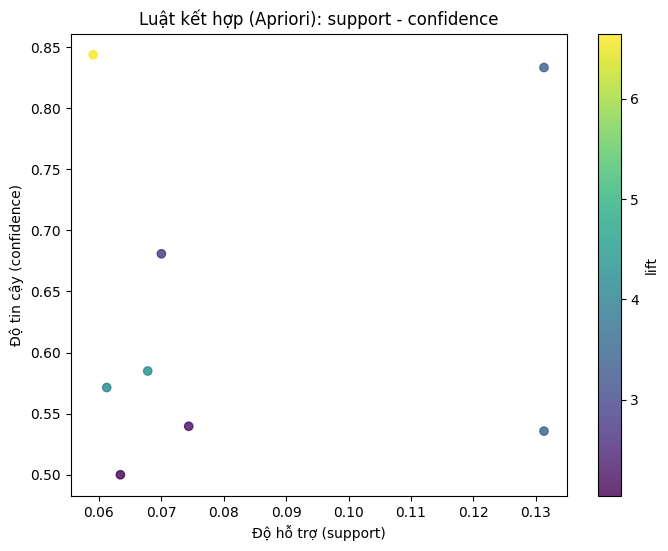

In [11]:
print("Hồng Kim Dung - 6451071009")

plt.figure(figsize=(8,6))
plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", alpha=.8)
plt.colorbar(label="lift"); plt.xlabel("Độ hỗ trợ (support)"); plt.ylabel("Độ tin cậy (confidence)")
plt.title("Luật kết hợp (Apriori): support - confidence"); plt.show()

## Câu 6: FP-Growth và so sánh với Apriori (min_sup = 5%, min_conf = 50%)

In [12]:
print("Hồng Kim Dung - 6451071009")

t0 = time.time()
fp_itemsets = fpgrowth(basket_sets, min_support=0.05, use_colnames=True)
t_fp = time.time() - t0
fp_rules = association_rules(fp_itemsets, metric="confidence", min_threshold=0.5)
print("FP-Growth: %d tập phổ biến, %d luật, %.2f giây" % (len(fp_itemsets), len(fp_rules), t_fp))
print("Apriori  : %d tập phổ biến, %d luật, %.2f giây" % (len(frequent_itemsets), len(rules), t_apriori))
fp_rules[["antecedents","consequents","support","confidence","lift"]]

Hồng Kim Dung - 6451071009
FP-Growth: 59 tập phổ biến, 8 luật, 0.04 giây
Apriori  : 59 tập phổ biến, 8 luật, 0.15 giây


,antecedents,consequents,support,confidence,lift
0,(ROUND SNACK BOXES SET OF4 WOODLAND),(ROUND SNACK BOXES SET OF 4 FRUITS),0.131291,0.535714,3.400298
1,(ROUND SNACK BOXES SET OF 4 FRUITS),(ROUND SNACK BOXES SET OF4 WOODLAND),0.131291,0.833333,3.400298
2,(WOODLAND CHARLOTTE BAG),(ROUND SNACK BOXES SET OF4 WOODLAND),0.063457,0.500000,2.040179
3,(PLASTERS IN TIN CIRCUS PARADE),(PLASTERS IN TIN WOODLAND ANIMALS),0.067834,0.584906,4.242887
4,(SPACEBOY LUNCH BOX),(ROUND SNACK BOXES SET OF4 WOODLAND),0.070022,0.680851,2.778116
5,(RED RETROSPOT CHARLOTTE BAG),(WOODLAND CHARLOTTE BAG),0.059081,0.843750,6.648168
6,(PLASTERS IN TIN WOODLAND ANIMALS),(ROUND SNACK BOXES SET OF4 WOODLAND),0.074398,0.539683,2.202098
7,(PLASTERS IN TIN SPACEBOY),(PLASTERS IN TIN WOODLAND ANIMALS),0.061269,0.571429,4.145125


In [13]:
print("Hồng Kim Dung - 6451071009")

col = "itemsets" if "itemsets" in fp_itemsets else "itemset"
a = set(frozenset(x) for x in frequent_itemsets[col]); b = set(frozenset(x) for x in fp_itemsets[col])
print("Hai thuật toán cho cùng tập phổ biến:", a == b)
ra = set((frozenset(x), frozenset(y)) for x, y in zip(rules["antecedents"], rules["consequents"]))
rb = set((frozenset(x), frozenset(y)) for x, y in zip(fp_rules["antecedents"], fp_rules["consequents"]))
print("Hai thuật toán cho cùng tập luật:", ra == rb)

Hồng Kim Dung - 6451071009
Hai thuật toán cho cùng tập phổ biến: True
Hai thuật toán cho cùng tập luật: True
